# 🏋️ BÀI THỰC NGHIỆM 01: TRÍCH XUẤT KHUNG XƯƠNG (POSE ESTIMATION) VỚI MEDIAPIPE

**Học phần:** Project 3 (Đồ án 3) — SoICT, Đại học Bách khoa Hà Nội (HUST)  
**Đề tài:** Phân tích dữ liệu video và gợi ý chỉnh sửa động tác cho người tập gym  
**Mục tiêu bài thực nghiệm:**
1. Sử dụng mô hình **MediaPipe Pose Landmarker (Heavy)** bóc tách 33 khớp 3D từ video quay thực tế.
2. Trực quan hóa khung xương trên các pha động tác (Đứng thẳng $\to$ Hạ xuống $\to$ Đáy squat).
3. Đánh giá độ tin cậy bắt khớp (Visibility & Presence) và tốc độ xử lý (FPS).
4. Xuất dữ liệu chuỗi tọa độ ra file JSON phục vụ tính góc sinh cơ học ở **Tầng 2**.

## 1. Khởi tạo Môi trường & Nạp Thư viện
Nhúng module lõi `PoseEngine` từ `backend/app/core/pose.py`.

In [1]:
import sys
import json
import time
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Thêm đường dẫn backend vào sys.path
project_root = Path.cwd().parent.parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'backend'))

from app.core.pose import PoseEngine

print(f'📂 Thư mục gốc dự án: {project_root}')
print('✅ Nạp thư viện và module PoseEngine thành công!')

📂 Thư mục gốc dự án: D:\Project\AI_Biomechanics_Coach
✅ Nạp thư viện và module PoseEngine thành công!


## 2. Kiểm tra Mô hình Pre-trained & Danh sách Video Mẫu
Hệ thống đã chuẩn bị sẵn 2 video mẫu có góc quay và định dạng khác nhau để đối chiếu:
* **Video 1 (`sample_squat.mp4`):** Barbell Back Squat quay dọc bằng điện thoại ($608 \times 1080$, góc bên hông $90^\circ$).
* **Video 2 (`sample_squat_2.mp4`):** Bodyweight Squat quay ngang Full HD ($1920 \times 1080$, góc bên hông $90^\circ$).


In [2]:
model_path = project_root / 'ai' / 'models' / 'pretrained' / 'pose_landmarker_heavy.task'
assert model_path.exists(), f'Thiếu file model tại {model_path}'
model_size_mb = model_path.stat().st_size / (1024 * 1024)
print(f'🤖 Mô hình: {model_path.name} ({model_size_mb:.2f} MB)')

videos_dir = project_root / 'data' / 'raw' / 'squats_good'
video_files = list(videos_dir.glob('*.mp4'))

for v in video_files:
    cap = cv2.VideoCapture(str(v))
    fps = cap.get(cv2.CAP_PROP_FPS)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    dur = total / fps if fps > 0 else 0
    print(f'📹 {v.name:20s} | Độ phân giải: {w}x{h} | FPS: {fps:.2f} | Frames: {total} | Thời lượng: {dur:.2f}s')
    cap.release()

🤖 Mô hình: pose_landmarker_heavy.task (29.24 MB)
📹 sample_squat.mp4     | Độ phân giải: 608x1080 | FPS: 29.97 | Frames: 614 | Thời lượng: 20.49s
📹 sample_squat_2.mp4   | Độ phân giải: 1920x1080 | FPS: 30.02 | Frames: 559 | Thời lượng: 18.62s


## 3. Khởi tạo PoseEngine & Chạy Trích xuất Khung xương
Chúng ta sẽ chạy trên video 1 (`sample_squat.mp4`) để bóc tách 33 khớp qua từng frame.

In [3]:
engine = PoseEngine(model_path=str(model_path))
target_video = project_root / 'data' / 'raw' / 'squats_good' / 'sample_squat.mp4'

start_time = time.time()
max_frames = 180
result = engine.extract_from_video(video_path=str(target_video), max_frames=max_frames)
elapsed = time.time() - start_time

print('=' * 50)
print('📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG:')
print(f'  • Tổng số frames xử lý: {result.total_frames}')
print(f'  • Số frames bắt dính người: {result.detected_frames_count}/{result.total_frames}')
print(f'  • Tỷ lệ nhận diện (Detection Rate): {result.detection_rate * 100:.2f}%')
print(f'  • Thời gian xử lý: {elapsed:.2f}s (Tốc độ ~{result.total_frames / elapsed:.1f} FPS trên CPU)')
print('=' * 50)

📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG:
  • Tổng số frames xử lý: 180
  • Số frames bắt dính người: 180/180
  • Tỷ lệ nhận diện (Detection Rate): 100.00%
  • Thời gian xử lý: 11.14s (Tốc độ ~16.2 FPS trên CPU)


## 4. Trực quan hóa Khung xương tại các Pha Động tác (Visualization)
Vẽ khung xương lên 3 khoảnh khắc then chốt:
1. **Pha 1 (Frame 20):** Setup / Đứng thẳng người.
2. **Pha 2 (Frame 55):** Eccentric / Đang hạ trọng tâm.
3. **Pha 3 (Frame 85):** Bottom / Xuống sâu nhất ở đáy squat.

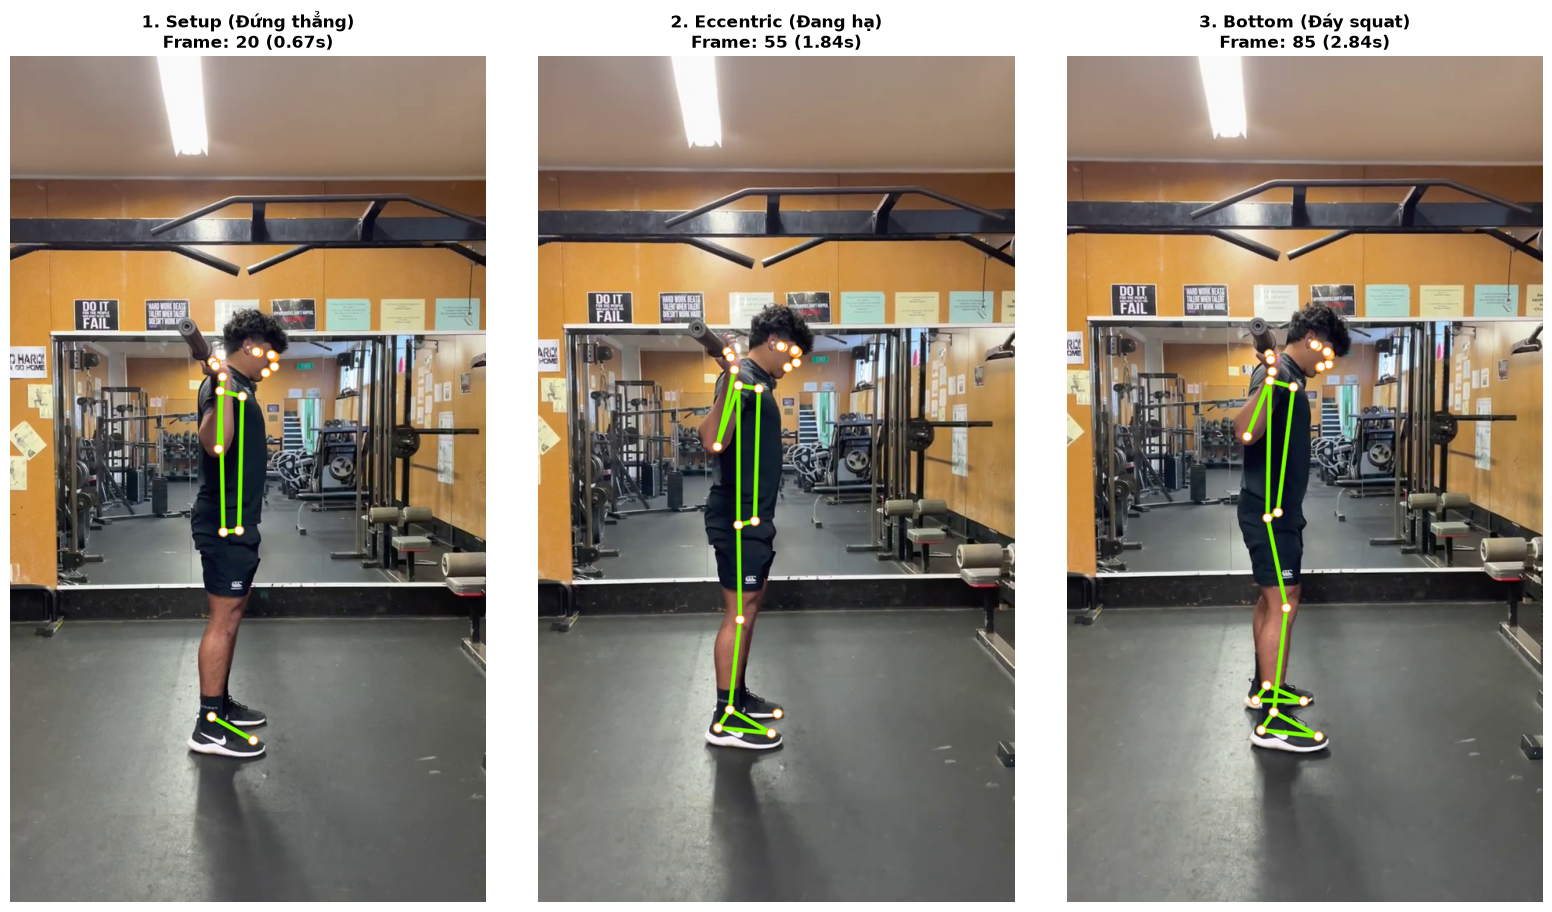

In [4]:
cap = cv2.VideoCapture(str(target_video))
frames_to_plot = [20, 55, 85]
phase_names = ['1. Setup (Đứng thẳng)', '2. Eccentric (Đang hạ)', '3. Bottom (Đáy squat)']

fig, axes = plt.subplots(1, 3, figsize=(16, 9))

for idx, (f_idx, p_name) in enumerate(zip(frames_to_plot, phase_names)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f_idx)
    ret, frame = cap.read()
    if ret and f_idx < len(result.frames):
        f_pose = result.frames[f_idx]
        if f_pose.is_detected:
            annotated = engine.draw_skeleton(frame, f_pose.landmarks, thickness=3, radius=5)
            rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(rgb)
            time_s = f_idx / result.fps
            axes[idx].set_title(f'{p_name}\nFrame: {f_idx} ({time_s:.2f}s)', fontsize=12, fontweight='bold')
            axes[idx].axis('off')

cap.release()
plt.tight_layout()
plt.show()

## 5. Phân tích Độ tin cậy (Confidence & Visibility) của các Khớp Trọng yếu
Trong phân tích bài tập Squat, 6 khớp quan trọng nhất là:
* **Khớp chi dưới:** Hông (Hip), Đầu gối (Knee), Mắt cá chân (Ankle), Gót chân (Heel).
* **Khớp thân trên:** Vai (Shoulder), Khuỷu tay (Elbow).

Chúng ta sẽ kiểm tra xem MediaPipe có nhận diện rõ ràng các khớp này xuyên suốt các frame hay không.

In [5]:
target_joints = ['left_hip', 'left_knee', 'left_ankle', 'left_heel', 'left_shoulder', 'left_foot_index']
vis_stats = {j: [] for j in target_joints}

for f in result.frames:
    if f.is_detected:
        for j_name in target_joints:
            lm = f.get_landmark(j_name)
            if lm:
                vis_stats[j_name].append(lm['visibility'])

print('📈 ĐỘ TIN CẬY TRUNG BÌNH CỦA CÁC KHỚP:')
for j_name, scores in vis_stats.items():
    mean_vis = np.mean(scores) if scores else 0
    min_vis = np.min(scores) if scores else 0
    status = '🟢 RẤT TỐT' if mean_vis > 0.85 else ('🟡 KHÁ' if mean_vis > 0.6 else '🔴 YẾU')
    print(f'  • Khớp {j_name:18s} | Trung bình: {mean_vis*100:.1f}% | Nhỏ nhất: {min_vis*100:.1f}% | Đánh giá: {status}')

📈 ĐỘ TIN CẬY TRUNG BÌNH CỦA CÁC KHỚP:
  • Khớp left_hip           | Trung bình: 100.0% | Nhỏ nhất: 100.0% | Đánh giá: 🟢 RẤT TỐT
  • Khớp left_knee          | Trung bình: 5.4% | Nhỏ nhất: 1.5% | Đánh giá: 🔴 YẾU
  • Khớp left_ankle         | Trung bình: 32.7% | Nhỏ nhất: 12.8% | Đánh giá: 🔴 YẾU
  • Khớp left_heel          | Trung bình: 45.9% | Nhỏ nhất: 23.1% | Đánh giá: 🔴 YẾU
  • Khớp left_shoulder      | Trung bình: 100.0% | Nhỏ nhất: 99.9% | Đánh giá: 🟢 RẤT TỐT
  • Khớp left_foot_index    | Trung bình: 55.2% | Nhỏ nhất: 28.8% | Đánh giá: 🔴 YẾU


## 6. Xuất Dữ liệu Tọa độ Ra JSON & Đóng gói Video Overlay
Kết quả được lưu vào:
* `data/processed/landmarks/sample_squat.json`
* `data/outputs/overlays/sample_pose_test.mp4`

In [6]:
out_json = project_root / 'data' / 'processed' / 'landmarks' / 'sample_squat.json'
export_dict = {
    'video_name': target_video.name,
    'fps': result.fps,
    'width': result.width,
    'height': result.height,
    'total_frames': result.total_frames,
    'detection_rate': result.detection_rate,
    'frames': [
        {
            'frame_idx': f.frame_idx,
            'timestamp_ms': f.timestamp_ms,
            'is_detected': f.is_detected,
            'landmarks': f.landmarks,
            'world_landmarks': f.world_landmarks
        }
        for f in result.frames
    ]
}

with open(out_json, 'w', encoding='utf-8') as f:
    json.dump(export_dict, f, indent=2, ensure_ascii=False)

json_size_mb = out_json.stat().st_size / (1024 * 1024)
print(f'💾 Đã lưu dữ liệu tọa độ chuỗi khớp tại: {out_json}')
print(f'📏 Dung lượng file JSON: {json_size_mb:.2f} MB')
print('🎉 TẦNG 1 ĐÃ HOÀN TẤT VÀ SẴN SÀNG LÀM ĐẦU VÀO CHO TẦNG 2!')

💾 Đã lưu dữ liệu tọa độ chuỗi khớp tại: D:\Project\AI_Biomechanics_Coach\data\processed\landmarks\sample_squat.json
📏 Dung lượng file JSON: 3.15 MB
🎉 TẦNG 1 ĐÃ HOÀN TẤT VÀ SẴN SÀNG LÀM ĐẦU VÀO CHO TẦNG 2!
